In [18]:
import numpy
import pandas
import seaborn

from matplotlib import pyplot

from fitting import TIMESERIES_TABLE_PATH
from realistic import PARAMS

In [19]:
pyplot.rcParams["figure.figsize"] = [12.8, 9.6]

In [20]:
def err(obs, model):
    scale = numpy.abs(obs)
    scale[scale == 0] = 1
    return numpy.abs(obs - model) / scale

In [38]:
params = {
    'a': 'fitted_a',
    'b': 'fitted_b',
    'e': 'fitted_e',
    'periapsis_phase': 'fitted_periapsis_phase',
    'Macc': 'fitted_Macc',
    'Porb': 'fitted_porb',
    'tau_eff': 'fitted_tau_eff',
}

In [22]:
results = pandas.read_pickle(TIMESERIES_TABLE_PATH)

In [23]:
results

,a,e,periapsis_phase,Macc,Porb,tau_eff,Mcomp,Rcomp,b,rv,...,baseline,pristine idx,realistic_idx,fitted_a,fitted_b,fitted_Macc,fitted_e,fitted_periapsis_phase,fitted_porb,fitted_tau_eff
0,10.481131,0,0,21.666667,2603.255789,0.287869,1.0,1.0,2.244898,"[103001.80976622521, 160526.10970583805, 19728...",...,365,29126,55739,1.175027,8.975169,7.124480,0.606678,5.129357,163.219540,0.153781
1,21.209509,0,0,8.125000,11810.761746,1.104199,1.0,1.0,1.428571,"[7323.339123802798, 10702.196639357833, 15733....",...,1095,30698,42484,0.639216,8.198449,0.500593,0.727734,5.546302,152.383717,0.355508
2,0.719686,0,0,14.375000,56.872871,0.099282,1.0,1.0,5.510204,"[-538072.3750950819, 312653.52809148416, 13617...",...,365,17443,95459,1.185682,0.348832,15.627015,0.361034,4.901828,115.649493,0.168140
3,75.431201,0,0,25.833333,46194.220679,2.397816,1.0,1.0,0.612245,"[2649.5941384233884, 6428.687778823793]",...,365,32960,14063,78.182725,0.722479,27.998468,0.198618,2.059864,46889.662712,2.372092
4,0.828643,0,0,9.166667,86.409234,0.137771,1.0,1.0,5.714286,"[48464.845342301065, -297311.19948561897, 2924...",...,1825,18448,50344,0.828663,5.591614,9.167528,0.000486,4.013539,86.408773,0.139409
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,0.409492,0,0,22.708333,19.656911,0.079760,1.0,1.0,1.020408,"[-720559.3419220042, 920104.0256163534, 487981...",...,1825,12532,23213,2.650793,3.939680,43.256920,0.468485,6.148528,236.958084,0.028908
4996,0.115140,0,0,9.166667,4.475544,0.057132,1.0,1.0,7.346939,"[-818015.747932484, -598079.2461316485, -27160...",...,1095,2154,19226,2.794569,1.567252,36.956190,0.212387,4.324211,276.967925,0.185566
4997,0.132571,0,0,21.666667,3.703208,0.043628,1.0,1.0,2.653061,"[-1802265.7983651124, -1546630.3433104393]",...,365,2841,39355,2.648260,2.182378,30.330242,0.817017,4.713402,281.227350,0.176322
4998,0.471487,0,0,24.791667,23.284280,0.078030,1.0,1.0,2.857143,"[1042140.45916064, 141053.96002857032, -111080...",...,365,13912,96485,1.430411,0.107258,37.526422,0.202597,6.047589,100.672406,0.133337


In [24]:
def plot_density(param):
    pyplot.hist2d(results[param], results[params[param]], bins=50, cmap='viridis',
                norm=pyplot.matplotlib.colors.LogNorm())
    pyplot.xlabel(param)
    pyplot.ylabel(params[param])
    pyplot.colorbar(label='Density')
    pyplot.show()

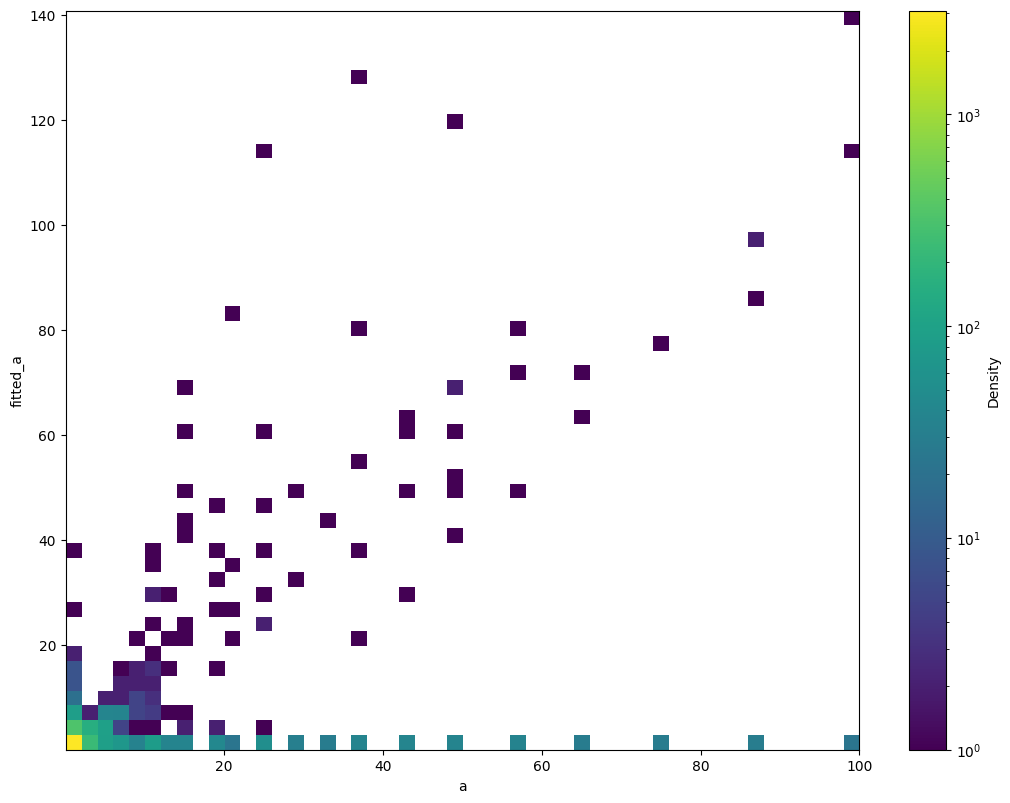

In [25]:
plot_density('a')

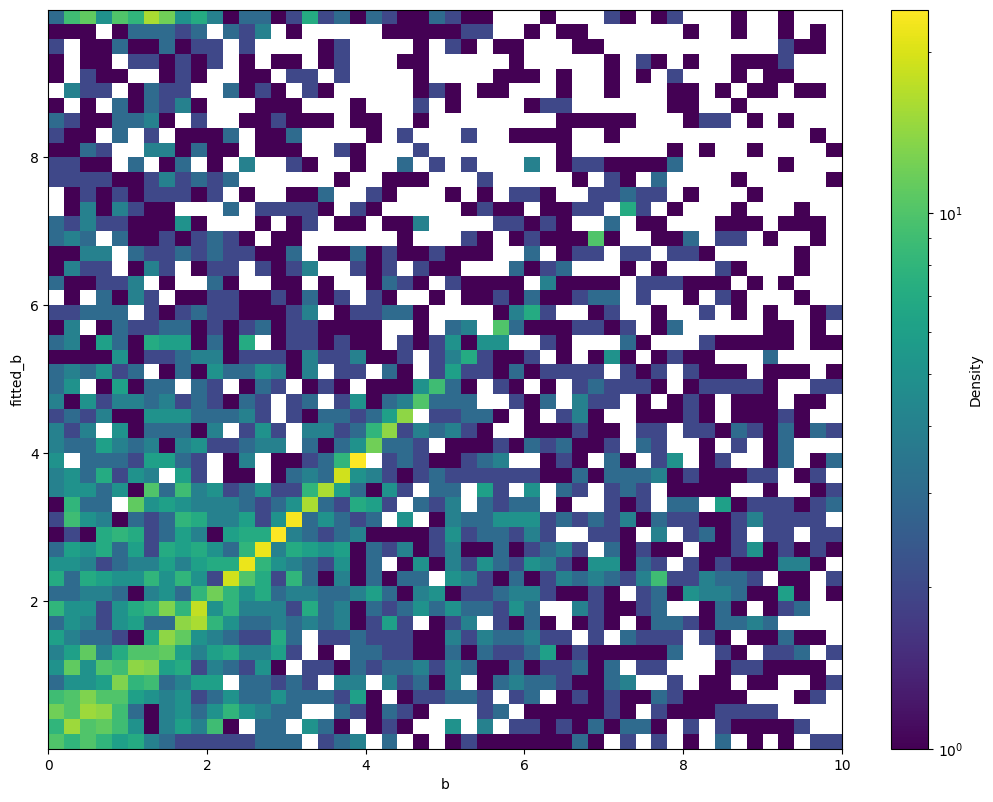

In [ ]:
plot_density('b')

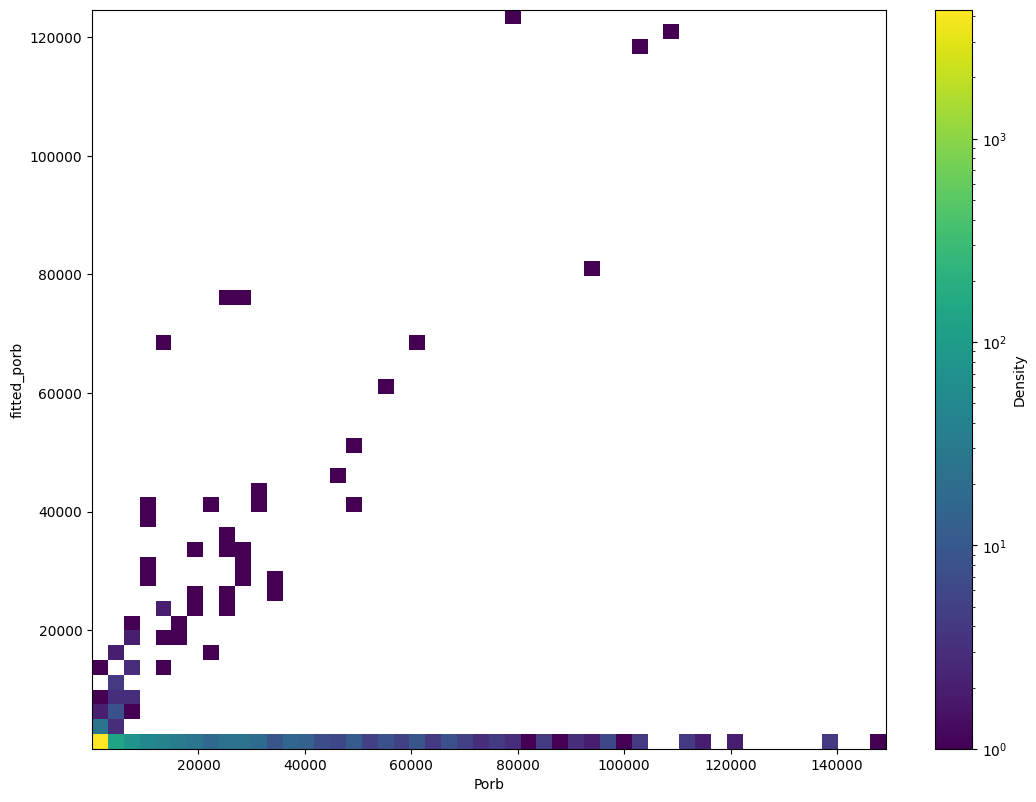

In [35]:
plot_density('Porb')

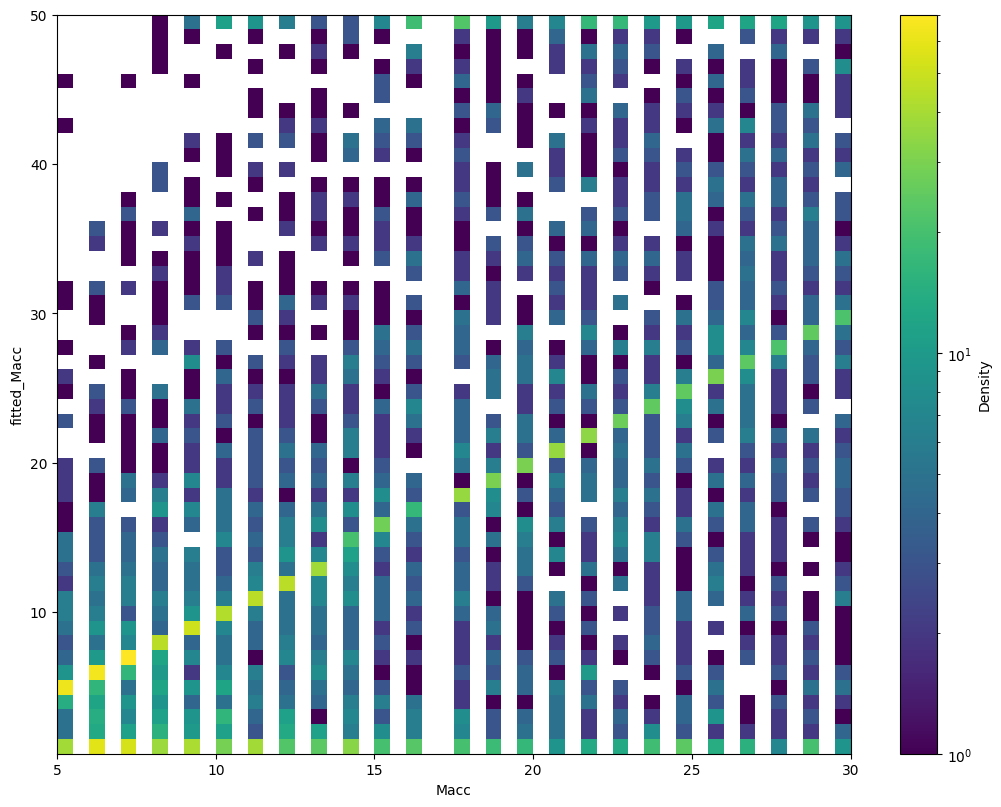

In [36]:
plot_density('Macc')

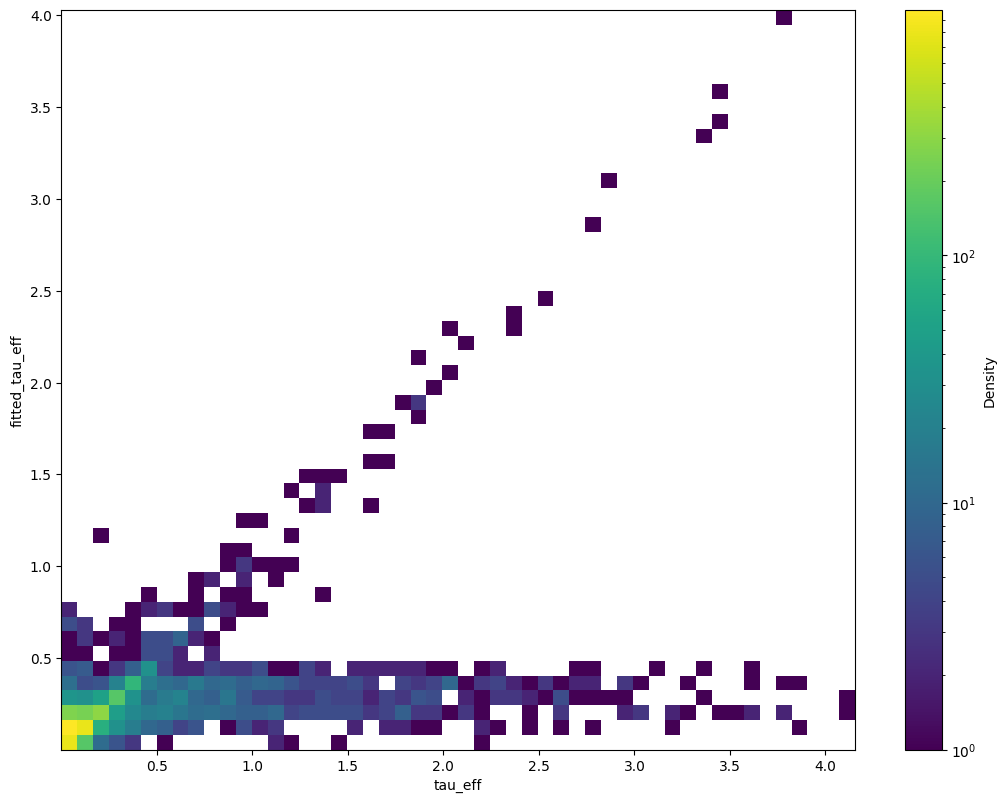

In [39]:
plot_density('tau_eff')

In [30]:
def plot_relation(x, y='RV accuracy', logx=True, logy=True, bins=20):
    for cadence, cadence_group in results.groupby('cadence'):
        baselines = numpy.sort(cadence_group['baseline'].unique())
        fig, axes = pyplot.subplots(1, len(baselines), figsize=(6 * len(baselines), 5), sharey=True)
        if len(baselines) == 1:
            axes = [axes]
        for ax, baseline in zip(axes, baselines):
            subset = cadence_group[cadence_group['baseline'] == baseline]
            xdata = subset[x]
            ydata = subset[y]
            diff = numpy.abs(subset[x] - subset[params[x]]) / subset[x]
            # Bin edges
            if logx:
                xbins = numpy.logspace(numpy.log10(xdata.min()), numpy.log10(xdata.max()), bins + 1)
            else:
                xbins = numpy.linspace(xdata.min(), xdata.max(), bins + 1)
            if logy:
                ybins = numpy.logspace(numpy.log10(ydata.min()), numpy.log10(ydata.max()), bins + 1)
            else:
                ybins = numpy.linspace(ydata.min(), ydata.max(), bins + 1)
            # Digitize to get bin indices
            xinds = numpy.digitize(xdata, xbins) - 1
            yinds = numpy.digitize(ydata, ybins) - 1
            mean_diff = numpy.full((bins, bins), numpy.nan)
            for i in range(bins):
                for j in range(bins):
                    mask = (xinds == i) & (yinds == j)
                    if numpy.any(mask):
                        mean_diff[i, j] = diff[mask].mean()
            # Use log scale for colors
            mesh = ax.pcolormesh(
                xbins, ybins, mean_diff.T,
                cmap='viridis',
                norm=pyplot.matplotlib.colors.LogNorm(vmin=numpy.nanmin(mean_diff), vmax=numpy.nanmax(mean_diff))
            )
            ax.set_title(f'Cadence: {cadence}, Baseline: {baseline}')
            ax.set_xlabel(x)
            ax.set_ylabel(y)
            if logx:
                ax.set_xscale('log')
            if logy:
                ax.set_yscale('log')
            fig.colorbar(mesh, ax=ax, label='Mean absolute difference (%)')
        pyplot.tight_layout()
        pyplot.show()

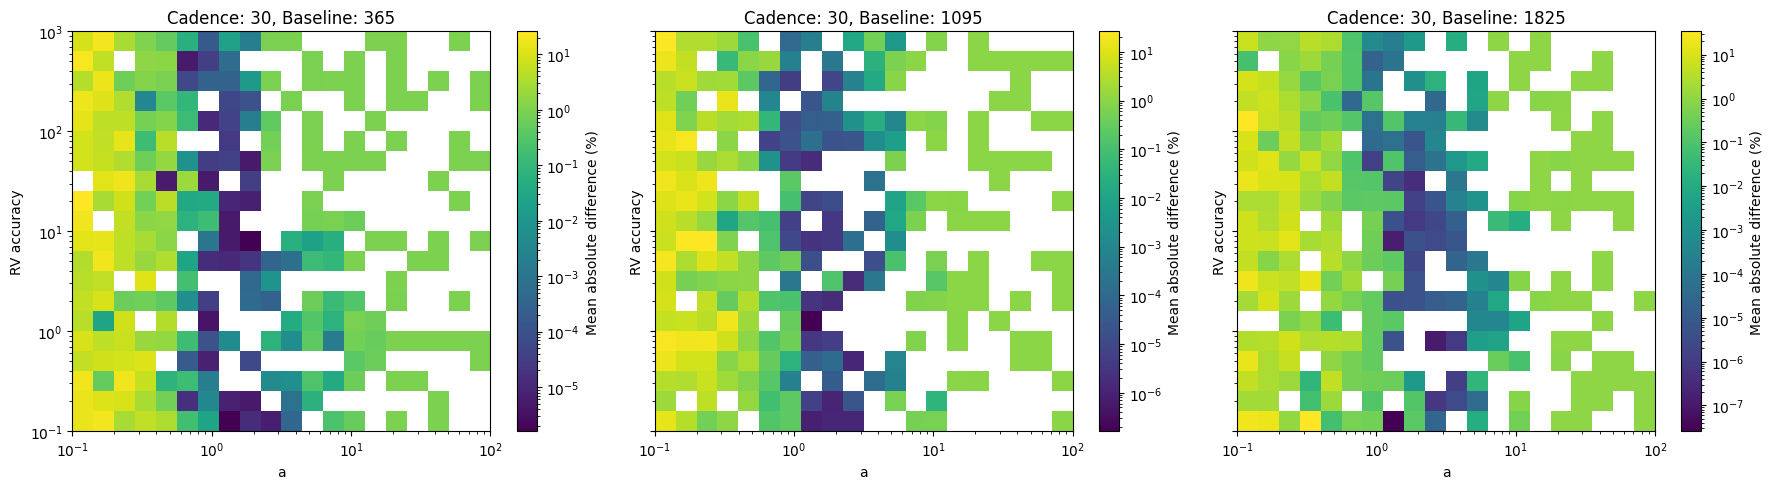

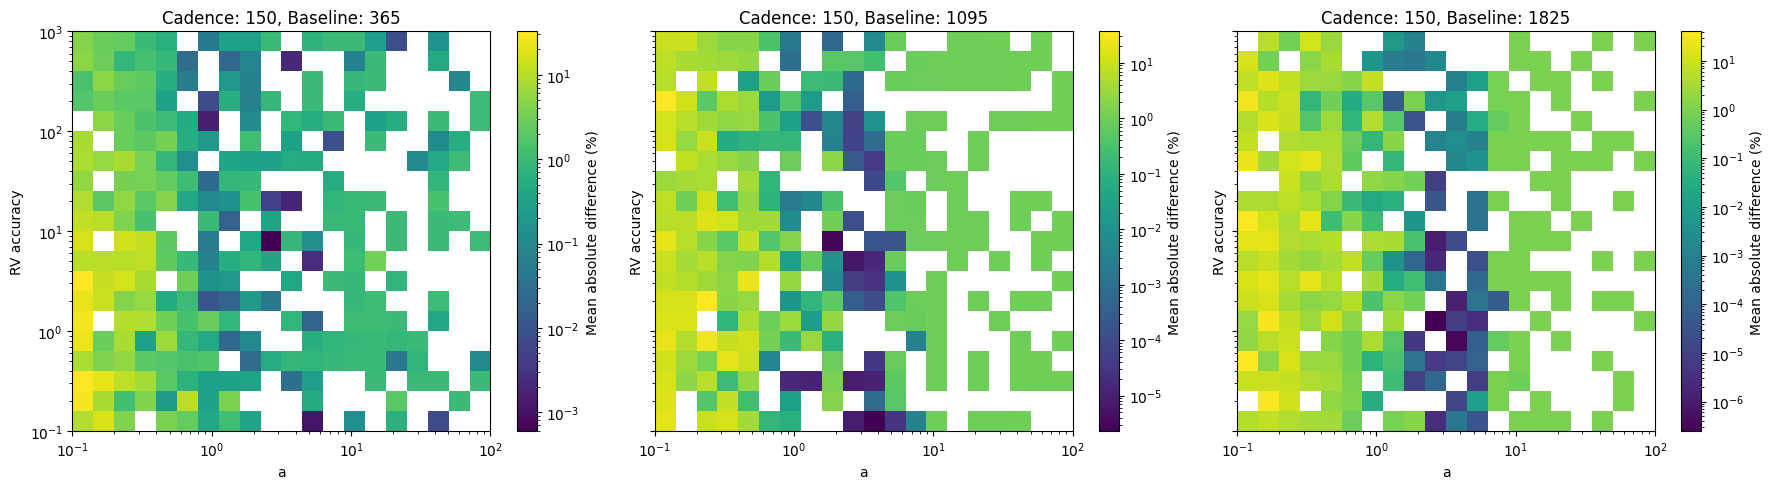

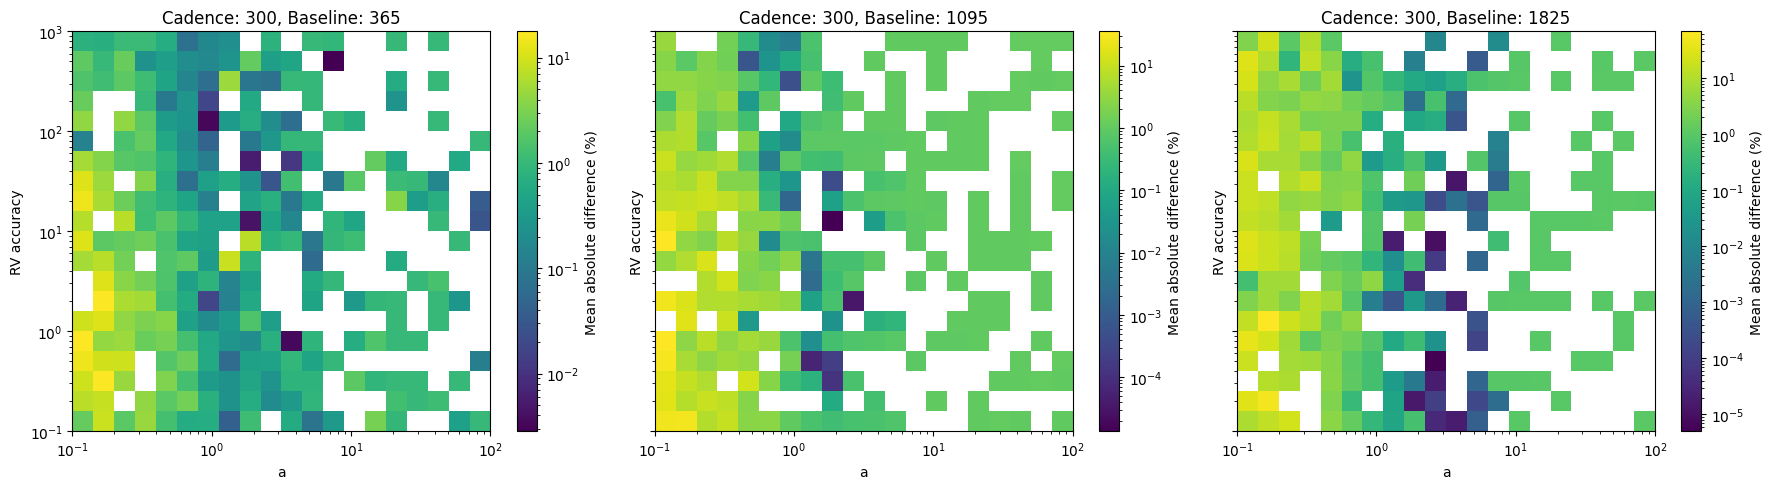

In [31]:
plot_relation('a')

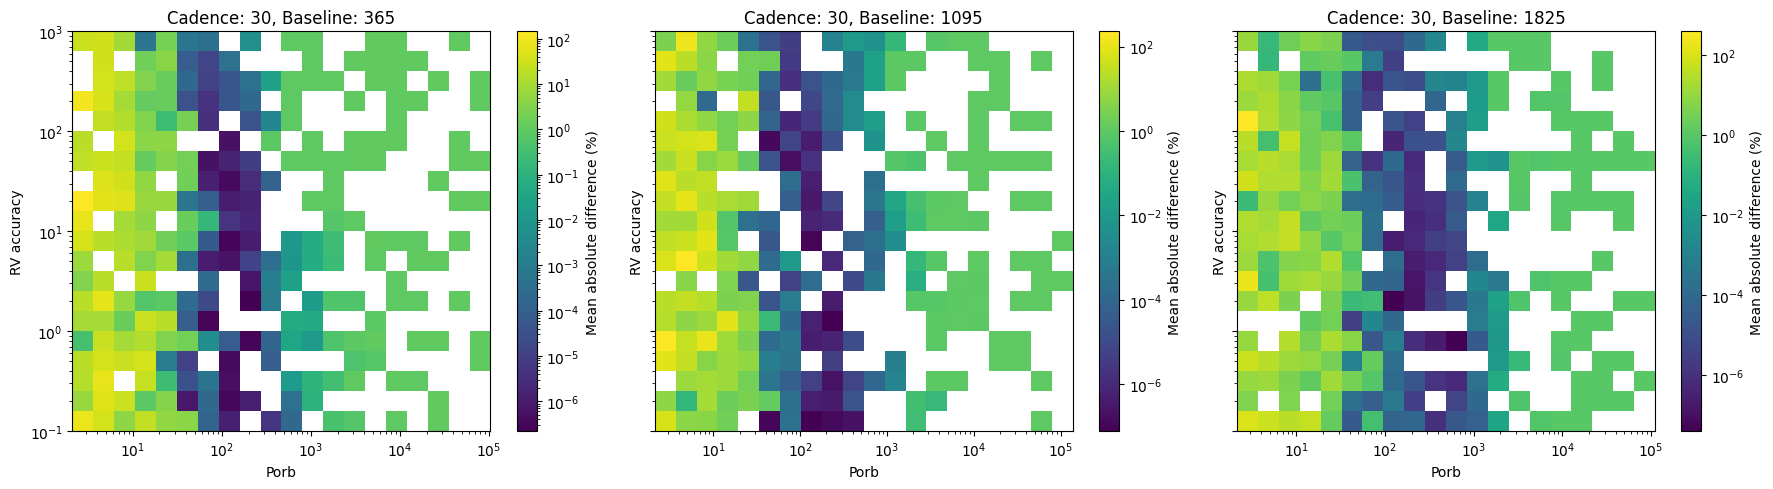

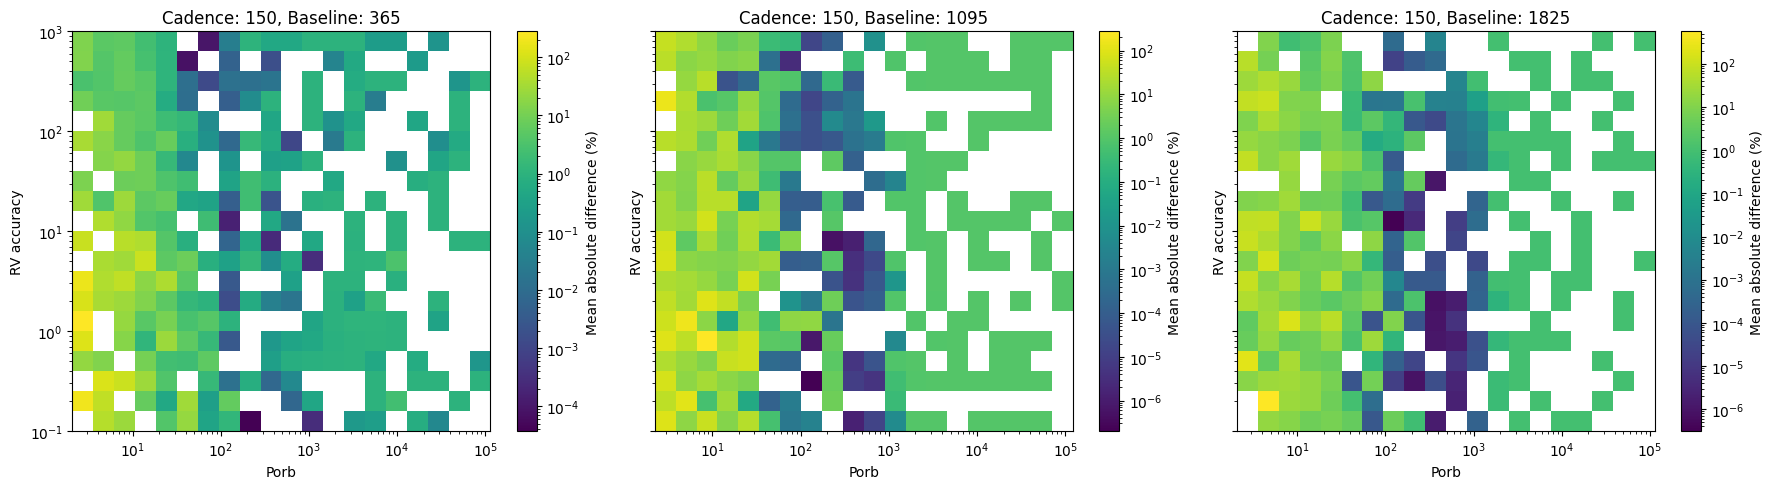

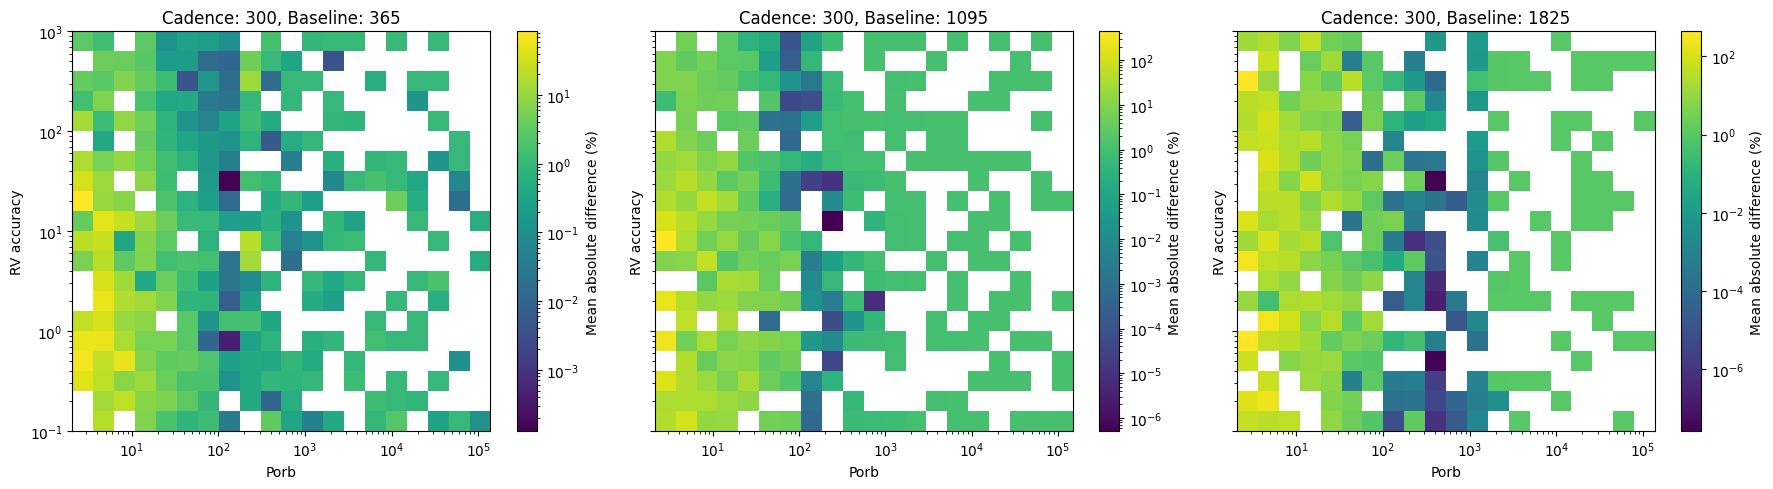

In [32]:
plot_relation('Porb')

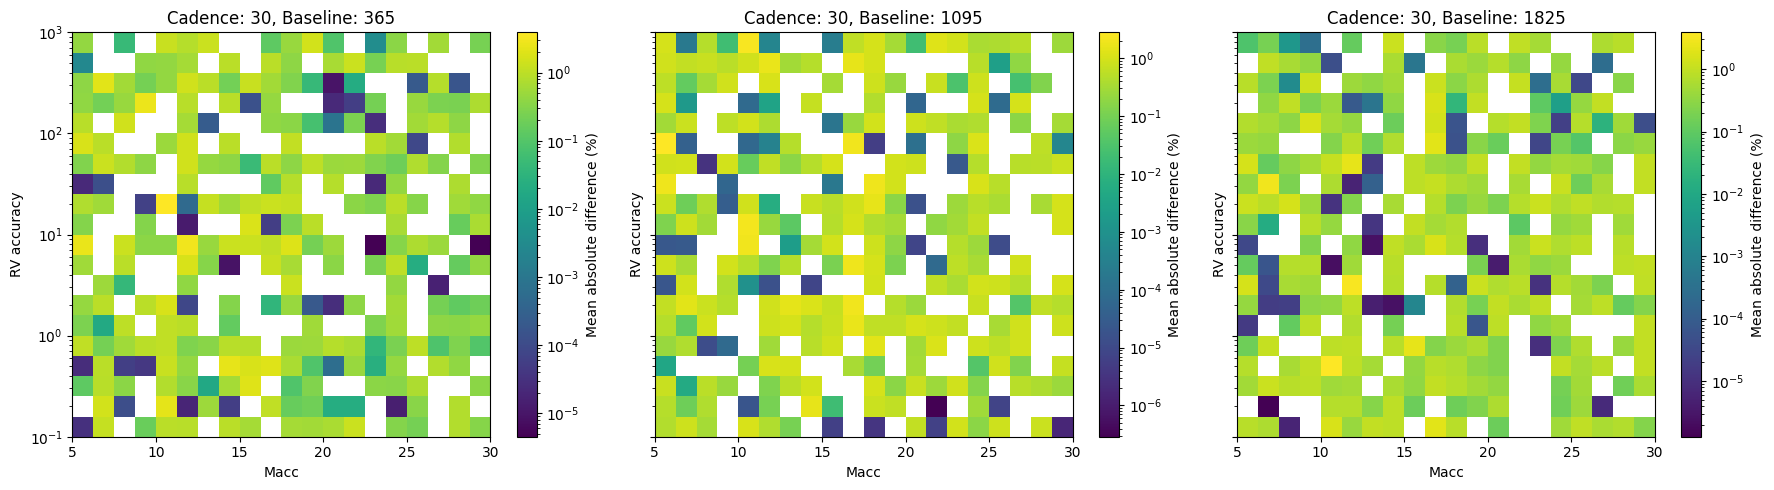

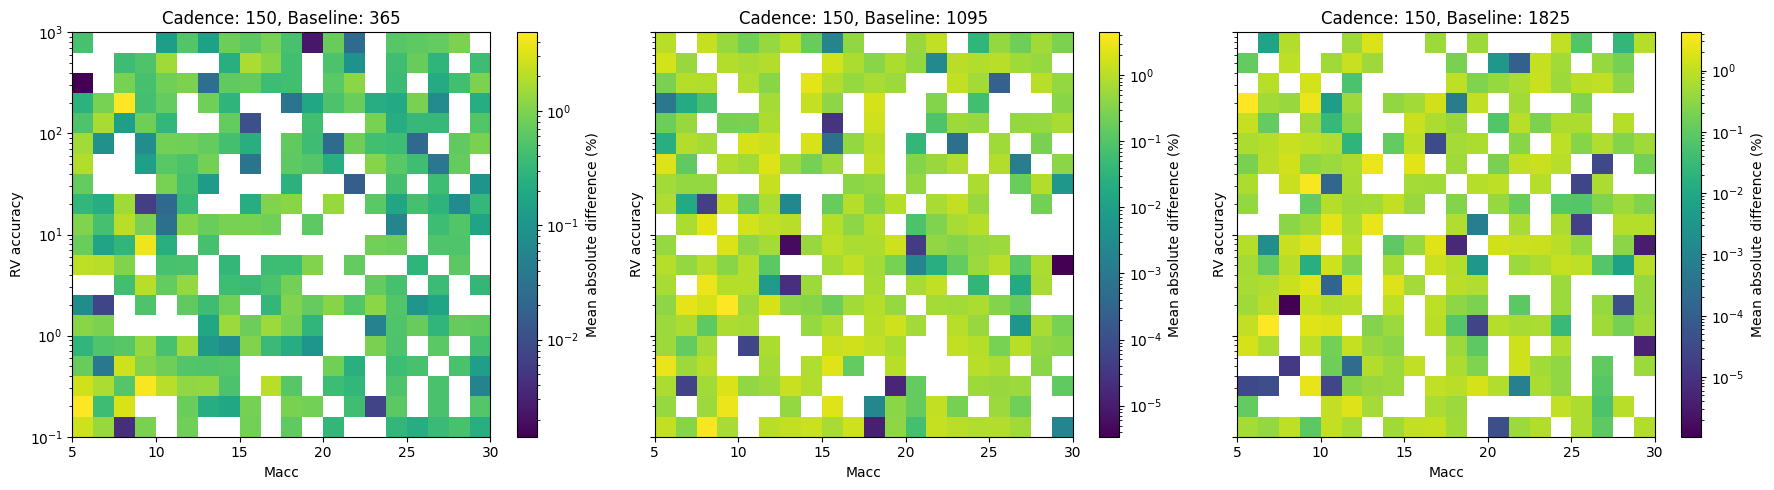

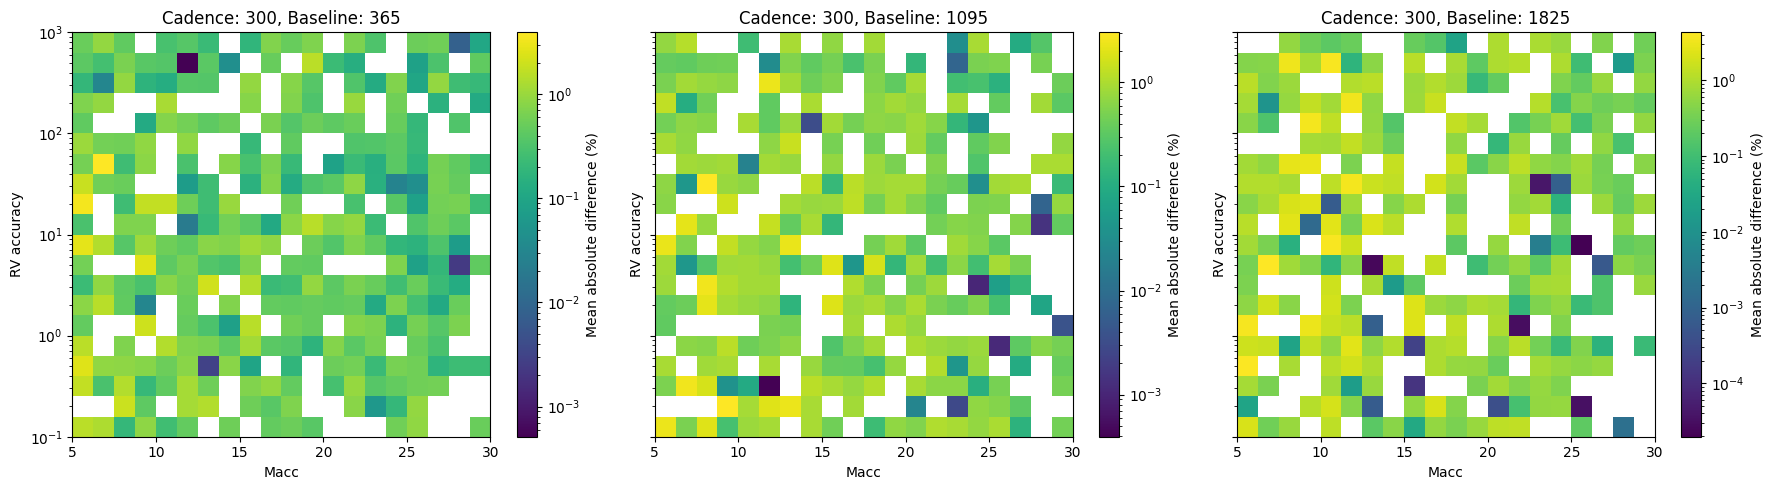

In [33]:
plot_relation('Macc', logx=False)

In [34]:
plot_relation('b', logx=False)

ValueError: Invalid vmin or vmax

Error in callback <function _draw_all_if_interactive at 0x11d62e520> (for post_execute), with arguments args (),kwargs {}:


ValueError: Invalid vmin or vmax

ValueError: Invalid vmin or vmax

<Figure size 1800x500 with 4 Axes>